# Radar de Viagens Públicas — tratamento e análise dos dados (2019–2026)

**Disciplina:** Análise de Dados e Big Data (A3) · **Fonte:** Portal da Transparência (CGU), Viagens a Serviço

**Pergunta de negócio:** *quanto o Governo Federal gasta com viagens a serviço, quem gasta, como gasta e quais viagens
merecem revisão, de forma comparável entre anos e órgãos?*

Este documento registra **todo o processo, da pergunta ao painel**, na ordem em que foi feito:

1. **Dados brutos**: o que baixamos do Portal da Transparência e como eles chegam.
2. **Diagnóstico**: tamanho, qualidade e armadilhas dos arquivos.
3. **Tratamento**: limpeza, enriquecimento e anonimização (passo a passo em 2023, depois para os 8 anos).
4. **Modelagem dimensional**: Star Schema (1 fato + 5 dimensões).
5. **Validação**: totais por ano e conferência com uma tabela independente.
6. **Análises**: cada pergunta, o código que a responde e o resultado.
7. **Insights e avaliação**: o que os dados permitem afirmar, com que confiança e para qual decisão.
8. **Do insight ao dashboard**: como cada insight virou um visual do painel.

> Cada etapa segue o formato **código → resultado → leitura**. Todos os números deste documento são gerados pelo próprio código abaixo.

## 0. Configuração

In [1]:
import zipfile, glob, os, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# zips AAAA_*_Viagens.zip baixados do Portal (não vão para o GitHub: > 100 MB cada)
PASTA_BRUTOS = Path('dados_brutos') if Path('dados_brutos').exists() else Path('..')
PASTA_TRATADOS = Path('data')     # saída do pipeline (usada pelo dashboard)

pd.set_option('display.max_columns', 30); pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
AZUL, LARANJA, AQUA, CINZA = '#2a78d6', '#eb6834', '#1baf7a', '#898781'
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e1e0d9', 'axes.axisbelow': True, 'font.size': 11})
def bi(x): return f'R$ {x/1e9:,.2f} bi'.replace(',', 'X').replace('.', ',').replace('X', '.')

## 1. Dados brutos

**Fonte:** Portal da Transparência (Controladoria-Geral da União), *Download de dados → Viagens a Serviço*
(https://portaldatransparencia.gov.br/download-de-dados/viagens). Um arquivo `.zip` por ano, cada um com 4 CSVs:

| Tabela | Unidade de registro | Uso no projeto |
|---|---|---|
| Viagem | 1 processo de viagem | datas, órgão, urgência, valores (diárias, passagens, outros, devolução) |
| Trecho | 1 deslocamento (origem → destino) | meio de transporte |
| Passagem | 1 emissão de passagem | não usada no dashboard |
| Pagamento | 1 lançamento de despesa | não usada (outra visão do mesmo gasto; somar duplicaria valores) |

In [2]:
zips = sorted(PASTA_BRUTOS.glob('20[0-9][0-9]_*_Viagens.zip'))
linhas = []
for z in zips:
    for info in zipfile.ZipFile(z).infolist():
        linhas.append({'arquivo zip': z.name, 'csv': info.filename,
                       'tamanho (MB)': round(info.file_size / 1e6)})
inventario = pd.DataFrame(linhas)
print(f'{len(zips)} arquivos zip · {inventario["tamanho (MB)"].sum()/1000:.1f} GB descompactados')
inventario.pivot_table(index='arquivo zip', columns=inventario['csv'].str.split('_').str[1].str.replace('.csv',''),
                       values='tamanho (MB)', aggfunc='sum')

8 arquivos zip · 7.0 GB descompactados


csv,Pagamento,Passagem,Trecho,Viagem
arquivo zip,,,,
2019_20261115_Viagens.zip,260,107,292,419
2020_20261115_Viagens.zip,96,29,112,181
2021_20261115_Viagens.zip,124,39,149,250
2022_20261115_Viagens.zip,200,71,238,387
2023_20260920_Viagens.zip,261,98,296,496
2024_20260920_Viagens.zip,256,101,281,475
2025_20260920_Viagens.zip,264,105,292,496
2026_20260920_Viagens.zip,147,64,160,294


**Leitura:** são ~7 GB de CSV em 8 anos. Arquivos desse tamanho não cabem num deploy gratuito, o que motivou o pipeline de compactação (seção 3).

### 1.1 Como os dados chegam (amostra crua de 2023)
Os CSVs usam `;` como separador, codificação **Latin-1**, números com vírgula decimal e datas `dd/mm/aaaa`.
Nome e CPF do servidor são mascarados aqui para não expor dados pessoais neste documento.

In [3]:
zf = zipfile.ZipFile(PASTA_BRUTOS / '2023_20260920_Viagens.zip')
bruto = pd.read_csv(zf.open('2023_Viagem.csv'), sep=';', encoding='latin1', dtype=str, keep_default_na=False)
amostra = bruto.sample(5, random_state=7).copy()
amostra['Nome'] = '*** omitido ***'; amostra['CPF viajante'] = '***'
print('Dimensões da tabela Viagem 2023:', bruto.shape)
amostra.T

Dimensões da tabela Viagem 2023: (833520, 22)


,278263,438434,435784,110831,685002
Identificador do processo de viagem,0000000000018962519,0000000000019157157,0000000000019153922,0000000000018760140,0000000000019478414
Número da Proposta (PCDP),003084/23,Informações p,Informações p,007689/23,019001/23
Situação,Realizada,Realizada,Realizada,Realizada,Realizada
Viagem Urgente,SIM,NÃO,NÃO,SIM,NÃO
Justificativa Urgência Viagem,A solicitação feita na presente data tendo em ...,Informação protegida por sigilo nos termos da ...,Informação protegida por sigilo nos termos da ...,POR NECESSIDADE DO SERVIÇO. AUTORIZADO PELA CH...,Sem informação
Código do órgão superior,39000,30000,30000,47000,44000
Nome do órgão superior,Ministério dos Transportes,Ministério da Justiça e Segurança Pública,Ministério da Justiça e Segurança Pública,Ministério do Planejamento e Orçamento,Ministério do Meio Ambiente e Mudança do Clima
Código órgão solicitante,39252,30108,30802,25205,44207
Nome órgão solicitante,Departamento Nacional de Infraestrutura de Tra...,Polícia Federal,Polícia Rodoviária Federal,Fundação Instituto Brasileiro de Geografia e E...,Instituto Chico Mendes de Conservação da Biodi...
CPF viajante,***,***,***,***,***


**Leitura:** tudo vem como texto. Os valores (`"1.234,56"`) e as datas precisam de conversão, e há campos de texto livre (`Destinos`, `Motivo`) e dados pessoais (`Nome`, `CPF viajante`).

## 2. Diagnóstico de qualidade (2023)

In [4]:
diag = {
    'linhas': len(bruto),
    'identificadores únicos': bruto['Identificador do processo de viagem'].nunique(),
    'IDs repetidos': bruto['Identificador do processo de viagem'].duplicated().sum(),
}
print(pd.Series(diag).to_string())
print('\nSituação:'); print(bruto['Situação'].value_counts().to_string())
print('\nViagem Urgente:'); print(bruto['Viagem Urgente'].value_counts().to_string())
vazios = (bruto.replace({'Sem informação': '', '-1': ''}) == '').mean().mul(100).round(1)
print('\n% de campos vazios / "Sem informação":'); print(vazios[vazios > 0].sort_values(ascending=False).to_string())

linhas                    833520
identificadores únicos    833518
IDs repetidos                  2

Situação:
Situação
Realizada        816710
Não realizada     16810

Viagem Urgente:
Viagem Urgente
SIM    518507
NÃO    315013

% de campos vazios / "Sem informação":
Função                          48.60
Descrição Função                48.60
Cargo                           39.10
Justificativa Urgência Viagem   23.60
CPF viajante                     0.60
Destinos                         0.40


In [5]:
destinos = bruto['Destinos'].sample(12, random_state=3).tolist()
print('Exemplos do campo Destinos (texto livre):'); [print('  ', d) for d in destinos];

Exemplos do campo Destinos (texto livre):
   Pinheiro/MA
   Querência do Norte/PR
   Bento Gonçalves/RS
   Lagarto/SE
   Palmas/TO
   Rurópolis/PA
   Foz do Iguaçu/PR
   Brasília/DF
   Jateí/MS
   Capistrano/CE, Baturité/CE
   Belo Horizonte/MG
   São Paulo/SP


**Achados do diagnóstico:**
- ~2% das viagens **não foram realizadas** e precisam sair das contas.
- Há **IDs repetidos** (poucos), removidos mantendo o primeiro registro.
- `Cargo` e `Função` têm muitos vazios, por isso não são usados como dimensão principal.
- `Destinos` é texto livre: `Cidade/UF` para destinos nacionais, `Cidade/País` para internacionais, vários destinos separados por vírgula, e há casos *"Informações protegidas por sigilo"*.
- Tabelas Trecho/Passagem/Pagamento têm **várias linhas por viagem**. Juntá-las com Viagem multiplicaria o gasto, por isso o valor vem **só da tabela Viagem**.

## 3. Tratamento — passo a passo (2023)

Cada passo abaixo é exatamente o que o arquivo `pipeline/preparar_dados.py` faz para todos os anos.

### 3.1 Filtrar realizadas, remover duplicados e converter tipos

In [6]:
v = bruto.rename(columns={
    'Identificador do processo de viagem': 'id', 'Número da Proposta (PCDP)': 'pcdp', 'Situação': 'situacao',
    'Viagem Urgente': 'urgente', 'Nome do órgão superior': 'orgao', 'Período - Data de início': 'ini',
    'Período - Data de fim': 'fim', 'Destinos': 'destinos', 'Valor diárias': 'diarias',
    'Valor passagens': 'passagens', 'Valor devolução': 'devolucao', 'Valor outros gastos': 'outros'})
antes = len(v)
v = v[v['situacao'] == 'Realizada'].drop_duplicates('id', keep='first').copy()

def money(s):  # "1.234,56" -> 1234.56
    return pd.to_numeric(s.str.replace('.', '', regex=False).str.replace(',', '.', regex=False), errors='coerce').fillna(0.0)
for c in ['diarias', 'passagens', 'devolucao', 'outros']:
    v[c] = money(v[c])
v['ini'] = pd.to_datetime(v['ini'], format='%d/%m/%Y', errors='coerce')
v['fim'] = pd.to_datetime(v['fim'], format='%d/%m/%Y', errors='coerce')
v = v[v['ini'].notna() & v['fim'].notna()]
print(f'{antes:,} linhas brutas -> {len(v):,} viagens realizadas únicas ({antes-len(v):,} removidas)')
v[['diarias', 'passagens', 'outros', 'devolucao']].describe().T

833,520 linhas brutas -> 816,710 viagens realizadas únicas (16,810 removidas)


,count,mean,std,min,25%,50%,75%,max
diarias,"816,710.00","1,774.28","5,042.97",0.00,285.57,879.92,"1,654.95","199,224.89"
passagens,"816,710.00","1,013.63","2,534.92",0.00,0.00,0.00,"1,316.29","186,723.29"
outros,"816,710.00",14.75,135.30,0.00,0.00,0.00,0.00,"59,668.18"
devolucao,"816,710.00",12.56,191.08,0.00,0.00,0.00,0.00,"34,240.41"


### 3.2 Criar as variáveis de análise
- **total** = diárias + passagens + outros gastos (devoluções ficam separadas)
- **dur** = fim − início + 1 dia; **custo_dia** = total ÷ dur
- **faixa_dur**: 1 dia · 2–3 · 4–7 · 8–30 · 31–90 · > 90 dias

In [7]:
v['total'] = v['diarias'] + v['passagens'] + v['outros']
v['dur'] = ((v['fim'] - v['ini']).dt.days + 1).clip(lower=1)
v['custo_dia'] = v['total'] / v['dur']
FAIXAS = [0, 1, 3, 7, 30, 90, 100000]
ROT = ['1 dia', '2–3 dias', '4–7 dias', '8–30 dias', '31–90 dias', '> 90 dias']
v['faixa_dur'] = pd.cut(v['dur'], FAIXAS, labels=ROT)
v['urgente'] = v['urgente'].eq('SIM')
print('Gasto total 2023:', bi(v['total'].sum()))
v['faixa_dur'].value_counts().reindex(ROT).to_frame('viagens')

Gasto total 2023: R$ 2,29 bi


,viagens
faixa_dur,
1 dia,136164
2–3 dias,236103
4–7 dias,290955
8–30 dias,135787
31–90 dias,13843
> 90 dias,3858


### 3.3 Escopo (nacional/internacional) e UF a partir do texto de `Destinos`

In [8]:
UF_RE = re.compile(r'/([A-Z]{2})$')
def classifica(destinos):
    if 'sigilo' in destinos.lower():
        return 'Sigiloso', 'SG'
    partes = [p.strip() for p in destinos.split(', ') if p.strip()]
    if not partes:
        return 'Não informado', 'ND'
    ufs = [UF_RE.search(p) for p in partes]
    escopo = 'Nacional' if all(ufs) else 'Internacional'
    return escopo, (ufs[0].group(1) if ufs[0] else 'EX')

res = v['destinos'].map(classifica)
v['escopo'], v['uf'] = res.str[0], res.str[1]
for d in ['Brasília/DF', 'Cajamar/SP, Campinas/SP', 'Lisboa/Portugal', 'Informações protegidas por sigilo']:
    print(f'{d:40s} -> {classifica(d)}')
print(); print(v['escopo'].value_counts(normalize=True).mul(100).round(1).to_string())

Brasília/DF                              -> ('Nacional', 'DF')
Cajamar/SP, Campinas/SP                  -> ('Nacional', 'SP')
Lisboa/Portugal                          -> ('Internacional', 'EX')
Informações protegidas por sigilo        -> ('Sigiloso', 'SG')

escopo
Nacional        82.70
Sigiloso        14.40
Internacional    2.90


### 3.4 Meio de transporte principal (tabela Trecho)
Uma viagem tem vários trechos. Para não multiplicar linhas, cada viagem recebe **um** meio principal, por prioridade:
se houver qualquer trecho aéreo, ela é *Aéreo*; senão vale o próximo da lista. Viagens sem trecho ficam como *Sem trecho*.

In [9]:
t = pd.read_csv(zf.open('2023_Trecho.csv'), sep=';', encoding='latin1', dtype=str, usecols=[0, 11], keep_default_na=False)
t.columns = ['id', 'modal']
print(f'Trechos 2023: {len(t):,} linhas para {t["id"].nunique():,} viagens')
RANK = {'Aéreo': 0, 'Marítimo': 1, 'Fluvial': 2, 'Ferroviário': 3, 'Rodoviário': 4,
        'Veículo Oficial': 5, 'Veículo Próprio': 6, 'Inválido': 7}
t['r'] = t['modal'].map(RANK).fillna(7)
principal = t.groupby('id')['r'].min().map({r: m for m, r in RANK.items()})
v['modal'] = v['id'].map(principal).fillna('Sem trecho')
v['modal'].value_counts(normalize=True).mul(100).round(1).to_frame('% viagens')

Trechos 2023: 1,819,626 linhas para 714,739 viagens


,% viagens
modal,
Veículo Oficial,43.40
Aéreo,32.40
Sem trecho,14.40
Rodoviário,5.30
Veículo Próprio,3.70
Fluvial,0.80
Ferroviário,0.00
Marítimo,0.00
Inválido,0.00


### 3.5 Anonimização (LGPD) e compactação
O arquivo final **não contém** nome, CPF nem identificador do viajante, apenas variáveis agregáveis. Os textos viram
categorias e o formato passa a ser Parquet com compressão zstd.

In [10]:
tam_bruto = zf.getinfo('2023_Viagem.csv').file_size + zf.getinfo('2023_Trecho.csv').file_size
tam_final = os.path.getsize(PASTA_TRATADOS / 'fato_viagem_2023.parquet')
print(f'2023: {tam_bruto/1e6:,.0f} MB de CSV  ->  {tam_final/1e6:,.1f} MB na tabela fato em Parquet  ({tam_bruto/tam_final:,.0f}x menor)')
print('Colunas da tabela fato:', list(pd.read_parquet(PASTA_TRATADOS / 'fato_viagem_2023.parquet').columns))

2023: 793 MB de CSV  ->  8.2 MB na tabela fato em Parquet  (96x menor)
Colunas da tabela fato: ['sk_tempo', 'sk_orgao', 'sk_destino', 'sk_modal', 'sk_duracao', 'urgente', 'dur', 'diarias', 'passagens', 'outros', 'devolucao', 'outlier', 'razao_mediana']


### 3.6 Como definir "viagem atípica"

A forma mais simples seria chamar de anomalia as **1.000 viagens mais caras**. Antes de adotar, testamos o que esse corte captura:

In [11]:
top = v.nlargest(1000, 'total')
print(f'Top 1.000 de 2023: duração mediana = {top["dur"].median():.0f} dias | '
      f'{(top["escopo"] == "Internacional").mean():.0%} internacionais | {(top["dur"] > 30).mean():.0%} com mais de 30 dias')

Top 1.000 de 2023: duração mediana = 365 dias | 10% internacionais | 95% com mais de 30 dias


**Leitura:** as viagens mais caras são quase sempre as **mais longas** (missões de meses), o que é esperado, não atípico.
Por isso a regra compara cada viagem com **viagens parecidas** (mesmo ano, escopo, faixa de duração e com/sem avião) e
usa o **custo por dia**. Testamos três versões:

In [12]:
d = v[v['total'] > 0].copy()
d['aereo'] = d['modal'].eq('Aéreo'); d['log_cd'] = np.log(d['custo_dia'])
def taxa(chaves, coluna, k=3):
    g = d.groupby(chaves, observed=True)[coluna]
    q1, q3 = g.transform(lambda s: s.quantile(.25)), g.transform(lambda s: s.quantile(.75))
    o = (d[coluna] > q3 + k * (q3 - q1)) & (d['total'] >= 1000)
    return o.mean() * 100, d.loc[o, 'total'].sum() / d['total'].sum() * 100
testes = {
    'A) custo/dia, pares = escopo+duração': taxa(['escopo', 'faixa_dur'], 'custo_dia'),
    'B) log(custo/dia), pares = escopo+duração': taxa(['escopo', 'faixa_dur'], 'log_cd'),
    'C) log(custo/dia), pares = escopo+duração+avião  (ADOTADA)': taxa(['escopo', 'faixa_dur', 'aereo'], 'log_cd'),
}
pd.DataFrame(testes, index=['% viagens marcadas', '% do gasto']).T.round(2)

,% viagens marcadas,% do gasto
"A) custo/dia, pares = escopo+duração",4.65,8.90
"B) log(custo/dia), pares = escopo+duração",3.11,4.06
"C) log(custo/dia), pares = escopo+duração+avião (ADOTADA)",0.78,1.08


**Leitura:** na regra A, 4–5% das viagens são "atípicas", demais para ser útil. O custo é muito assimétrico (log-normal) e
mistura viagens com e sem passagem aérea. Com a escala log e o avião no grupo (regra C), cerca de **1% das viagens** é
marcado, uma lista que uma equipe de controle consegue de fato revisar.

### 3.7 Execução para os 8 anos
O mesmo código, empacotado em `pipeline/preparar_dados.py`, roda para todos os zips:
```bash
python pipeline/preparar_dados.py --zips "dados_brutos"
```

In [13]:
print(open('pipeline/preparar_dados.py', encoding='utf-8').read())

"""Pipeline: zips brutos do Portal da Transparência (Viagens a Serviço) -> parquets compactos do dashboard.

Uso (a partir da pasta dashboard/):
    python pipeline/preparar_dados.py --zips ".."

Saídas em data/ — modelo dimensional (Star Schema):
    fato_viagem_<ano>.parquet  FATO: uma linha por viagem REALIZADA (medidas + chaves), sem nome/CPF/ID do viajante
    dim_tempo.parquet          DIMENSÃO calendário (data de início da viagem) + fator IPCA
    dim_orgao.parquet          DIMENSÃO órgão superior
    dim_destino.parquet        DIMENSÃO destino (escopo, UF, região, coordenadas)
    dim_modal.parquet          DIMENSÃO meio de transporte principal
    dim_duracao.parquet        DIMENSÃO faixa de duração
    casos_<ano>.parquet        casos para revisão (detalhe, com PCDP para conferência no Portal)
    resumo_situacao.parquet    viagens realizadas x não realizadas por ano (controle de qualidade)
"""
import argparse
import glob
import os
import re
import zipfile

import numpy as np

## 4. Modelagem dimensional (Star Schema)

A área de preparação é separada em **1 tabela fato** (uma linha por viagem, só com medidas e chaves) e **5 dimensões**
(descrições), ligadas por **chaves substitutas** `sk_*` em relação **muitos-para-um**:

```
            dim_tempo        dim_orgao
                 \              /
   dim_destino — FATO_VIAGEM — dim_modal
                      |
                 dim_duracao
```

| Tabela | Grão | Conteúdo |
|---|---|---|
| **fato_viagem** | 1 viagem realizada | sk_tempo, sk_orgao, sk_destino, sk_modal, sk_duracao · diárias, passagens, outros, devolução, duração, urgente, outlier |
| dim_tempo | 1 dia | data, ano, mês, trimestre, dia da semana, fim de semana, **fator IPCA**, urgência confiável |
| dim_orgao | 1 órgão superior | nome do órgão |
| dim_destino | escopo + UF | escopo, UF, nome, região, latitude/longitude |
| dim_modal | 1 meio de transporte | meio, categoria (aéreo, terrestre, aquaviário) |
| dim_duracao | 1 faixa | faixa, dias mín/máx |

In [14]:
fato = pd.concat([pd.read_parquet(a) for a in sorted(PASTA_TRATADOS.glob('fato_viagem_*.parquet'))], ignore_index=True)
dims = {n: pd.read_parquet(PASTA_TRATADOS / f'{n}.parquet') for n in ['dim_tempo', 'dim_orgao', 'dim_destino', 'dim_modal', 'dim_duracao']}
print(f'fato_viagem: {len(fato):,} linhas x {fato.shape[1]} colunas')
for n, d in dims.items():
    print(f'{n:12s}: {len(d):>5,} linhas · colunas: {", ".join(d.columns)}')
# integridade referencial: toda chave da fato existe na dimensão
chk = {'sk_tempo': 'dim_tempo', 'sk_orgao': 'dim_orgao', 'sk_destino': 'dim_destino', 'sk_modal': 'dim_modal', 'sk_duracao': 'dim_duracao'}
print('\nIntegridade referencial:', all(fato[k].isin(dims[t][k]).all() for k, t in chk.items()))
fato.head(3)

fato_viagem: 5,080,763 linhas x 13 colunas
dim_tempo   : 2,804 linhas · colunas: sk_tempo, data, ano, mes, nome_mes, trimestre, dia_semana, nome_dia, fim_de_semana, fator_ipca, urgencia_confiavel
dim_orgao   :    35 linhas · colunas: sk_orgao, orgao
dim_destino :    54 linhas · colunas: sk_destino, escopo, uf, nome_uf, regiao, lat, lon
dim_modal   :     9 linhas · colunas: sk_modal, modal, categoria
dim_duracao :     6 linhas · colunas: sk_duracao, faixa_dur, dias_min, dias_max

Integridade referencial: True


,sk_tempo,sk_orgao,sk_destino,sk_modal,sk_duracao,urgente,dur,diarias,passagens,outros,devolucao,outlier,razao_mediana
0,20190101,13,54,7,2,False,3,518.86,0.00,0.00,0.00,False,1.37
1,20190101,13,54,7,3,False,4,"1,007.24",0.00,0.00,0.00,False,1.44
2,20190101,13,54,7,3,False,4,"1,007.24","3,306.56",0.00,0.00,False,6.18


In [15]:
# consulta típica do modelo: fato JOIN dimensões -> base analítica
t = dims['dim_tempo'].set_index('sk_tempo')
df = fato.merge(dims['dim_orgao'], on='sk_orgao').merge(dims['dim_destino'][['sk_destino', 'escopo', 'uf']], on='sk_destino') \
         .merge(dims['dim_modal'][['sk_modal', 'modal']], on='sk_modal').merge(dims['dim_duracao'][['sk_duracao', 'faixa_dur']], on='sk_duracao')
df['ano'] = t['ano'].reindex(df['sk_tempo']).to_numpy(); df['mes'] = t['mes'].reindex(df['sk_tempo']).to_numpy()
df['dia_semana_ini'] = t['dia_semana'].reindex(df['sk_tempo']).to_numpy()
df['fator'] = t['fator_ipca'].reindex(df['sk_tempo']).to_numpy()
df['faixa_dur'] = pd.Categorical(df['faixa_dur'], ROT, ordered=True)
df['total'] = df['diarias'].astype(float) + df['passagens'] + df['outros']
df['real'] = df['total'] * df['fator']
FATOR = t.groupby('ano')['fator_ipca'].first().to_dict()
print(f'Base analítica: {len(df):,} viagens · {df["ano"].min()}–{df["ano"].max()} · '
      f'{sum(os.path.getsize(a) for a in PASTA_TRATADOS.glob("*.parquet"))/1e6:.0f} MB no total (de ~7 GB de CSV)')

Base analítica: 5,080,763 viagens · 2019–2026 · 50 MB no total (de ~7 GB de CSV)


## 5. Validação

### 5.1 Totais por ano

In [16]:
anual = df.groupby('ano').agg(viagens=('total', 'size'), gasto_nominal=('total', 'sum'), gasto_real=('real', 'sum'))
anual['fator IPCA'] = anual.index.map(FATOR)
anual['ticket médio'] = anual['gasto_nominal'] / anual['viagens']
anual.assign(gasto_nominal=anual['gasto_nominal'].map(bi), gasto_real=anual['gasto_real'].map(bi))

,viagens,gasto_nominal,gasto_real,fator IPCA,ticket médio
ano,,,,,
2019,828962,"R$ 1,30 bi","R$ 1,82 bi",1.39,"1,573.49"
2020,322942,"R$ 0,55 bi","R$ 0,73 bi",1.33,"1,700.61"
2021,414045,"R$ 0,79 bi","R$ 0,96 bi",1.21,"1,912.27"
2022,646377,"R$ 1,55 bi","R$ 1,77 bi",1.14,"2,399.97"
2023,816710,"R$ 2,29 bi","R$ 2,50 bi",1.09,"2,802.66"
2024,789503,"R$ 2,39 bi","R$ 2,49 bi",1.04,"3,025.80"
2025,805625,"R$ 2,50 bi","R$ 2,50 bi",1.00,"3,103.53"
2026,456599,"R$ 1,31 bi","R$ 1,31 bi",1.00,"2,876.63"


O fator IPCA leva cada ano a **preços de dezembro de 2025** (ex.: R$ 1,00 de 2019 ≈ R$ 1,39 de 2025).

### 5.2 Conferência com uma fonte independente (tabela Pagamento, 2023)
A tabela **Pagamento** registra os lançamentos financeiros de cada viagem, separada da tabela Viagem. Se o tratamento estiver
correto, os dois totais (todas as situações) devem ser praticamente iguais.

In [17]:
pag = pd.read_csv(zf.open('2023_Pagamento.csv'), sep=';', encoding='latin1', dtype=str, usecols=['Valor'], keep_default_na=False)
total_pag = money(pag['Valor']).sum()
b = bruto[['Valor diárias', 'Valor passagens', 'Valor outros gastos']].apply(money).sum().sum()
print(f'Tabela Viagem (bruto, todas as situações): {bi(b)}')
print(f'Tabela Pagamento (soma dos lançamentos):   {bi(total_pag)}')
print(f'Diferença: {abs(b - total_pag) / b:.2%}')

Tabela Viagem (bruto, todas as situações): R$ 2,33 bi
Tabela Pagamento (soma dos lançamentos):   R$ 2,33 bi
Diferença: 0.12%


**Leitura:** as duas tabelas, publicadas separadamente, chegam ao mesmo total com diferença desprezível. Isso confirma a
conversão de valores e a escolha da tabela Viagem como fonte do gasto. Somar as duas, por outro lado, **duplicaria** o gasto.

In [18]:
sit = pd.read_parquet(PASTA_TRATADOS / 'resumo_situacao.parquet').pivot_table(index='ano', columns='situacao', values='n')
sit['% não realizadas'] = sit.iloc[:, 0] / sit.sum(axis=1) * 100
sit

situacao,Não realizada,Realizada,% não realizadas
ano,,,
2019,"19,594.00","828,962.00",2.31
2020,"20,885.00","322,942.00",6.07
2021,"11,079.00","414,046.00",2.61
2022,"16,209.00","646,377.00",2.45
2023,"16,810.00","816,710.00",2.02
2024,"10,830.00","789,503.00",1.35
2025,"8,767.00","805,628.00",1.08
2026,"5,378.00","456,599.00",1.16


## 6. Análises

### 6.1 Evolução do gasto: nominal x corrigido pela inflação

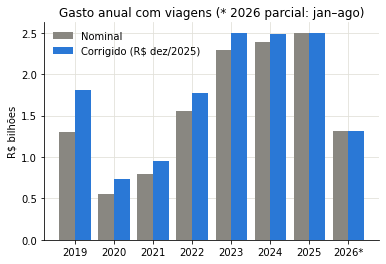

Queda 2019->2020: 60%
2025 / 2019: 1.92x nominal  |  1.38x já descontada a inflação
2023 a 2025 (real): R$ 2,50 bi · R$ 2,49 bi · R$ 2,50 bi


In [19]:
fig, ax = plt.subplots()
x = np.arange(len(anual)); w = .4
ax.bar(x - w/2, anual['gasto_nominal']/1e9, w, color=CINZA, label='Nominal')
ax.bar(x + w/2, anual['gasto_real']/1e9, w, color=AZUL, label='Corrigido (R$ dez/2025)')
ax.set_xticks(x, [str(a) + ('*' if a == 2026 else '') for a in anual.index]); ax.set_ylabel('R$ bilhões')
ax.set_title('Gasto anual com viagens (* 2026 parcial: jan–ago)'); ax.legend(frameon=False); plt.show()
r = anual['gasto_real']; n = anual['gasto_nominal']
print(f'Queda 2019->2020: {1 - r[2020]/r[2019]:.0%}')
print(f'2025 / 2019: {n[2025]/n[2019]:.2f}x nominal  |  {r[2025]/r[2019]:.2f}x já descontada a inflação')
print(f'2023 a 2025 (real): ' + ' · '.join(bi(r[a]) for a in [2023, 2024, 2025]))

**Leitura:** a pandemia derrubou o gasto em ~60%. Depois disso, o gasto passou o nível de 2019 a partir de 2022. Em 2025 ele
é **1,9× o de 2019 em valores nominais** e ainda **~1,4× já descontada a inflação**, ou seja, o crescimento é real, mas
menor do que os números nominais sugerem.

### 6.2 Comparação justa com 2026 (ano parcial)

In [20]:
cnt = df[df['ano'].isin([2025, 2026])].groupby(['ano', 'mes']).size().unstack(0)
cnt['2026 / 2025'] = cnt[2026] / cnt[2025]
corte = int(max(m for m in cnt.index if cnt.loc[m, '2026 / 2025'] >= .85))
print('Viagens por mês (2025 x 2026) e razão — meses recentes ainda incompletos:'); print(cnt.round(2).to_string())
ytd = df[df['mes'] <= corte].groupby('ano')['real'].sum()
print(f'\nCorte automático: jan–{corte:02d}.  Gasto real no mesmo período de cada ano:')
print(ytd.map(bi).to_string())
print(f'\n2026 x 2025 (jan–{corte:02d}): {ytd[2026]/ytd[2025]-1:+.1%}')

Viagens por mês (2025 x 2026) e razão — meses recentes ainda incompletos:
ano      2025      2026  2026 / 2025
mes                                 
1   26,727.00 27,698.00         1.04
2   44,479.00 43,002.00         0.97
3   63,359.00 75,013.00         1.18
4   60,935.00 64,157.00         1.05
5   72,764.00 86,064.00         1.18
6   70,905.00 73,501.00         1.04
7   55,542.00 42,359.00         0.76
8   79,224.00 44,361.00         0.56
9   88,718.00    444.00         0.01
10  89,948.00       NaN          NaN
11  93,030.00       NaN          NaN
12  59,994.00       NaN          NaN

Corte automático: jan–06.  Gasto real no mesmo período de cada ano:
ano
2019    R$ 0,91 bi
2020    R$ 0,42 bi
2021    R$ 0,42 bi
2022    R$ 0,76 bi
2023    R$ 1,04 bi
2024    R$ 1,21 bi
2025    R$ 1,18 bi
2026    R$ 1,09 bi

2026 x 2025 (jan–06): -7.8%


**Leitura:** comparar o total de 2026 com o de anos completos seria injusto. Comparando o mesmo intervalo de meses, dá para dizer
se 2026 está acima ou abaixo de 2025. Julho e agosto de 2026 ainda têm muito menos registros que em 2025 (registros atrasados) e ficam fora do corte.
No 1º semestre, **2026 gastou cerca de 8% menos que 2025**, com volume de viagens parecido ou maior. É o primeiro sinal de queda desde 2020, mas ainda precisa ser confirmado quando o ano fechar.

### 6.3 Órgãos: gasto absoluto x indicadores normalizados

In [21]:
org = df.groupby('orgao', observed=True).agg(viagens=('total', 'size'), gasto=('real', 'sum'),
        mediana=('real', 'median'), atipicos=('outlier', 'mean'))
org['ticket'] = org['gasto'] / org['viagens']; org['% gasto'] = org['gasto'] / org['gasto'].sum() * 100
org = org.sort_values('gasto', ascending=False)
print(f'Top 3 órgãos = {org["% gasto"].head(3).sum():.0f}% do gasto (2019–2026, R$ dez/2025)')
org.head(10).assign(gasto=org['gasto'].head(10).map(bi),
                    atipicos=org['atipicos'].head(10)*1000).rename(columns={'atipicos': 'atípicos por mil'})

Top 3 órgãos = 61% do gasto (2019–2026, R$ dez/2025)


,viagens,gasto,mediana,atípicos por mil,ticket,% gasto
orgao,,,,,,
Ministério da Justiça e Segurança Pública,1125179,"R$ 4,85 bi","1,500.68",27.56,"4,307.06",34.41
Ministério da Defesa,968501,"R$ 2,06 bi","1,257.26",1.98,"2,125.91",14.62
Ministério da Educação,1002585,"R$ 1,67 bi",746.16,2.78,"1,667.34",11.87
Ministério do Meio Ambiente e Mudança do Clima,256266,"R$ 0,65 bi",963.49,2.09,"2,519.12",4.58
Ministério da Saúde,176904,"R$ 0,55 bi","1,509.74",2.10,"3,119.61",3.92
Ministério da Fazenda,210653,"R$ 0,49 bi","1,020.29",3.85,"2,318.69",3.47
Ministério da Previdência Social,142985,"R$ 0,44 bi","1,259.14",4.40,"3,077.96",3.12
Ministério das Relações Exteriores,29358,"R$ 0,36 bi","7,066.84",4.16,"12,397.44",2.58
Presidência da República,90339,"R$ 0,28 bi","1,400.87",8.87,"3,153.32",2.02


**Leitura:** Justiça e Segurança Pública e Defesa lideram em gasto absoluto principalmente pelo **volume** (operações de PF, PRF,
Forças Armadas). Ticket médio, mediana e taxa de atípicos por mil viagens são as métricas para comparar órgãos de tamanhos diferentes.

### 6.4 Concentração do gasto

As  1% viagens mais caras = 19% do gasto
As  5% viagens mais caras = 38% do gasto
As 10% viagens mais caras = 51% do gasto
As 20% viagens mais caras = 68% do gasto

Média: R$ 2,772   Mediana: R$ 1,172


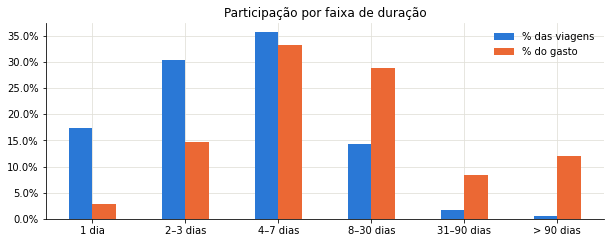

               v     g
faixa_dur             
1 dia      17.40  2.70
2–3 dias   30.40 14.60
4–7 dias   35.70 33.40
8–30 dias  14.40 28.90
31–90 dias  1.70  8.30
> 90 dias   0.50 12.00


In [22]:
vals = np.sort(df['real'].to_numpy())[::-1]; cum = np.cumsum(vals) / vals.sum()
for p in [1, 5, 10, 20]:
    print(f'As {p:>2}% viagens mais caras = {cum[len(vals)*p//100 - 1]:.0%} do gasto')
print(f'\nMédia: R$ {df["real"].mean():,.0f}   Mediana: R$ {df["real"].median():,.0f}')
fx = df.groupby('faixa_dur', observed=False).agg(v=('real', 'size'), g=('real', 'sum')).reindex(ROT)
fx = fx / fx.sum() * 100
ax = fx.plot.bar(color=[AZUL, LARANJA], rot=0, figsize=(10, 3.6)); ax.legend(['% das viagens', '% do gasto'], frameon=False)
ax.set_title('Participação por faixa de duração'); ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlabel(''); plt.show()
print(fx.round(1).to_string())

**Leitura:** o gasto é muito concentrado. Poucas viagens (as longas e as internacionais) consomem uma parcela grande do
orçamento, e a **média engana**, sendo mais que o dobro da mediana. Para auditoria, começar pelas viagens longas cobre muito dinheiro com pouco esforço.

### 6.5 Urgência: regra, não exceção

**Achado de qualidade:** antes de analisar a urgência, verificamos o campo ano a ano e mês a mês. Em 2019 **todas**
as viagens vêm como "NÃO", e em 2020 a taxa salta de ~20% para ~60% em junho. Isso indica uma mudança no preenchimento
do sistema, não no comportamento dos órgãos. Por isso a urgência só é comparada a partir de **2021**.

% urgentes por ano:
ano
2019    0.00
2020   44.90
2021   60.00
2022   60.60
2023   62.50
2024   58.70
2025   57.60
2026   57.40


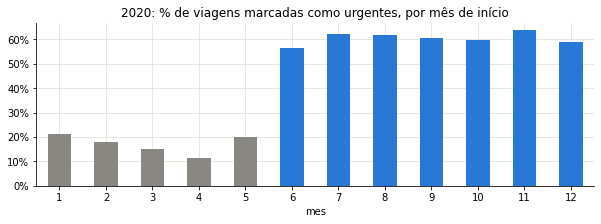

In [23]:
print('% urgentes por ano:'); print((df.groupby('ano')['urgente'].mean() * 100).round(1).to_string())
m20 = df[df['ano'] == 2020].groupby('mes')['urgente'].mean() * 100
ax = m20.plot.bar(color=[CINZA if m < 6 else AZUL for m in m20.index], rot=0, figsize=(10, 3))
ax.set_title('2020: % de viagens marcadas como urgentes, por mês de início'); ax.yaxis.set_major_formatter(mtick.PercentFormatter()); plt.show()

In [24]:
URG_DESDE = 2021
du = df[df['ano'] >= URG_DESDE]
u = du.groupby('ano').agg(pct_urg=('urgente', 'mean'))
tk = du.groupby(['ano', 'urgente'])['real'].mean().unstack()
u['ticket urgente'] = tk[True]; u['ticket programada'] = tk[False]; u['diferença'] = tk[True] / tk[False] - 1
u['pct_urg'] *= 100
print(u.round(2).to_string())
print(f'\nDesde {URG_DESDE}: {du["urgente"].mean():.1%} das viagens são marcadas como urgentes.')

      pct_urg  ticket urgente  ticket programada  diferença
ano                                                        
2021    60.05        2,478.36           2,064.94       0.20
2022    60.61        2,848.99           2,583.11       0.10
2023    62.54        3,172.96           2,879.96       0.10
2024    58.68        3,297.05           2,952.56       0.12
2025    57.61        3,251.97           2,901.78       0.12
2026    57.36        2,958.73           2,766.18       0.07

Desde 2021: 59.6% das viagens são marcadas como urgentes.


**Leitura:** **cerca de 60% de todas as viagens** são marcadas como urgentes desde 2021. Portanto, encontrar muitas viagens
urgentes num grupo de casos caros não é, por si só, um alerta: a urgência virou o padrão do sistema, e viagens urgentes custam
em média mais. Isso aponta para um problema de **planejamento**, não para casos isolados.

### 6.6 O viés do "fim de semana"

In [25]:
df['fds'] = (df['dur'] >= 7) | ((df['dia_semana_ini'] + df['dur'] - 1) >= 5)
f = df.groupby('faixa_dur', observed=False)['fds'].mean().reindex(ROT) * 100
print('% de viagens que incluem sábado ou domingo, por duração:'); print(f.round(1).to_string())
top1000 = df.nlargest(1000, 'total')
print(f'\nTop 1.000 mais caras: {top1000["fds"].mean():.1%} incluem fim de semana · duração mediana {top1000["dur"].median():.0f} dias')
print(f'Viagens curtas (até 3 dias) iniciadas no sábado/domingo: {(df.loc[df["dur"]<=3, "dia_semana_ini"]>=5).mean():.1%}')

% de viagens que incluem sábado ou domingo, por duração:
faixa_dur
1 dia          6.40
2–3 dias      20.60
4–7 dias      56.30
8–30 dias    100.00
31–90 dias   100.00
> 90 dias    100.00

Top 1.000 mais caras: 99.9% incluem fim de semana · duração mediana 365 dias
Viagens curtas (até 3 dias) iniciadas no sábado/domingo: 8.2%


**Leitura:** toda viagem de 7 dias ou mais inclui um fim de semana, e as 1.000 mais caras duram em mediana vários meses.
Por isso "viagem cara que inclui fim de semana" é **efeito da duração**, não um indício. O indicador correto é a parcela de
**viagens curtas que começam no fim de semana**.

### 6.7 Casos atípicos ao longo do tempo e por órgão

In [26]:
at = df.groupby('ano').agg(casos=('outlier', 'sum'), taxa=('outlier', 'mean'))
at['taxa por mil'] = at['taxa'] * 1000
at['valor (real, R$ mi)'] = (df[df['outlier']].groupby('ano')['real'].sum() / 1e6).round(1)
at.drop(columns='taxa')

,casos,taxa por mil,"valor (real, R$ mi)"
ano,,,
2019,6806,8.21,26.50
2020,4057,12.56,20.00
2021,6807,16.44,30.50
2022,2248,3.48,16.50
2023,6114,7.49,27.00
2024,6036,7.65,33.80
2025,6513,8.08,32.20
2026,3370,7.38,18.50


In [27]:
o = df.groupby('orgao', observed=True).agg(n=('outlier', 'size'), taxa=('outlier', 'mean'))
o = o[o['n'] >= 10000].sort_values('taxa', ascending=False).head(10); o['taxa por mil'] = o['taxa'] * 1000
o[['n', 'taxa por mil']]

,n,taxa por mil
orgao,,
Ministério da Justiça e Segurança Pública,1125179,27.56
Controladoria-Geral da União,13693,18.33
Ministério dos Direitos Humanos e Cidadania,19328,12.06
Presidência da República,90339,8.87
Ministério da Gestão e da Inovação em Serviços Públicos,14730,6.31
"Ministério do Desenvolvimento e Assistência Social, Família e Combate à Fome",19075,5.40
Ministério dos Transportes,82007,4.95
Ministério da Previdência Social,142985,4.40
Ministério das Relações Exteriores,29358,4.16


**Leitura:** com a taxa por mil viagens, dá para comparar órgãos grandes e pequenos de forma justa. No dashboard, cada caso
aparece com a **PCDP** (número do processo), o que permite conferi-lo no Portal sem expor o servidor.

## 7. Insights e avaliação

Cada insight recebe uma **avaliação de confiança** (alta: medida direta e robusta; média: depende de um campo autodeclarado,
de um ano parcial ou de uma regra estatística) e a **decisão** que ele permite tomar.

| # | Insight | Confiança | Decisão que habilita | Seção |
|---|---|---|---|---|
| 1 | O gasto caiu ~60% na pandemia e depois **superou o nível de 2019**: em 2025 é 1,92× o de 2019 em valores nominais e **1,38× já descontada a inflação**. | Alta | Rever o teto orçamentário de diárias/passagens e exigir justificativa para o presencial | 6.1 |
| 2 | No mesmo período (jan–jun), **2026 gasta ~8% menos que 2025**, com volume parecido: primeiro sinal de queda desde a pandemia. | Média (ano parcial) | Acompanhar mês a mês se a queda se confirma | 6.2 |
| 3 | Justiça, Defesa e Educação concentram **61% do gasto**, mas por **volume**. Normalizando, a taxa de atípicos por mil viagens muda o ranking. | Média | Comparar órgãos pela taxa e cobrar explicação de quem está acima | 6.3, 6.7 |
| 4 | O gasto é **concentrado**: 1% das viagens = 19% do gasto, 10% = metade; viagens com mais de 30 dias são 2,2% das viagens e 20% do gasto. A média (R$ 2.772) é 2,4× a mediana (R$ 1.172). | Alta | Priorizar a auditoria nas viagens longas e de maior valor | 6.4 |
| 5 | **A urgência é a regra** (~60% das viagens desde 2021), e viagens urgentes custam em média 10% a 12% mais. | Média (campo autodeclarado) | Antecedência mínima de compra e justificativa formal da urgência | 6.5 |
| 6 | O campo de urgência **não era preenchido antes de jun/2020**: comparações com 2019 seriam falsas. | Alta | Limitar indicadores de urgência a 2021+ | 6.5 |
| 7 | "Viagem cara que inclui fim de semana" é **efeito da duração**, não um indício. | Alta | Usar o indicador de viagens curtas iniciadas no fim de semana | 6.6 |
| 8 | A regra de pares marca **~0,8% das viagens** como atípicas, uma lista viável para auditoria e verificável pela PCDP. | Média (regra estatística) | Usar a lista como fila de auditoria amostral | 3.6, 6.7 |

### Limites
- A base **não mede reuniões online**: a queda de 2020 coincide com a pandemia, mas não prova que o trabalho remoto causou a economia.
- Caso atípico é um **sinal para revisão**, não prova de irregularidade.
- `Destinos` é texto livre e a UF considerada é a do 1º destino.
- O campo de urgência só é confiável a partir de jun/2020.
- O gasto vem da tabela Viagem (valores registrados no processo), não da execução orçamentária (tabela Pagamento).

## 8. Do insight ao dashboard

O painel foi desenhado **a partir das análises acima**: cada insight virou um visual, e o tipo de gráfico foi escolhido pelo que
o dado precisa mostrar.

| Insight | Visual no painel | Página | Por que este gráfico |
|---|---|---|---|
| 1 · Evolução e inflação | Barras por ano + toggle IPCA | Evolução | Barras comparam magnitudes entre categorias discretas (anos); o toggle mostra o efeito da inflação |
| 2 · 2026 parcial | Barras jan–jun de cada ano (2026 destacado) | Evolução | Mesmo intervalo em todos os anos evita comparar ano parcial com ano cheio |
| — · Sazonalidade | Linhas mês a mês por ano | Evolução | Linhas mostram tendência contínua no tempo; destaque em 2019, 2020 e 2025 |
| — · Composição | Barras empilhadas (diárias, passagens, outros) | Evolução | Mostram o total e a parte de cada componente ao mesmo tempo |
| 3 · Órgãos | Barras horizontais (top 10) + bolhas volume × ticket + tabela | Órgãos | Barras horizontais leem nomes longos; bolhas separam "muitas viagens" de "viagens caras"; tabela permite ordenar |
| 4 · Concentração | Barras agrupadas (% viagens × % gasto) + curva de Pareto | Perfil | A comparação lado a lado e a curva acumulada mostram a desproporção |
| — · Destinos | Mapa de bolhas por UF | Perfil | Dado geográfico; o tamanho da bolha codifica o gasto |
| 5 · Urgência | Linhas urgentes × programadas | Radar | Duas séries no tempo com a mesma escala |
| 7 · Fim de semana | Barras % por faixa de duração | Radar | Explica o viés de forma visual |
| 8 · Casos atípicos | Barras (taxa por mil) + tabela com PCDP | Radar | Taxa normalizada para comparar órgãos; tabela para ação |
| Todos | Cartões de KPI com mini-linha de tendência + cartões de insight | Resumo | Número em destaque para leitura em segundos; a tendência dá contexto |

**Filtros (interatividade):** período (ano), órgão superior, escopo (nacional/internacional/sigiloso), urgência, correção pela
inflação (liga/desliga) e botão de restaurar. Todos os visuais das páginas analíticas respondem aos filtros.

### Valor gerado
A plataforma transforma ~7 GB de CSV em um painel de ~50 MB que responde em segundos: **quanto se gasta, quem gasta, como gasta e o que merece revisão**,
com comparações justas (inflação, mesmo período, normalização por volume) e sem expor dados pessoais.